# Redline 911: geometry, braking allocation and roll calibration

## Results

This notebook compares the original and corrected production physics under the same 13-car, five-case, two-repeat protocol. The comparison tool rejects different effective inputs, scenario definitions or prepared asset hashes. Baseline raw runs remain in `artifacts/handling-study-20261023`; candidate runs remain in `artifacts/handling-study-911-fix-20261023`.

The production change allocates service-brake demand by measured wheel load and raises narrow-track anti-roll stiffness to preserve the baseline's small-angle roll resistance. Mass, geometry, tire friction, steering and vertical spring/damping settings are retained. The roll change is an arcade tuning calibration rather than a recovered real-car specification.

In [1]:
from pathlib import Path
import json, math, statistics
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Markdown, display
ROOT=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/"Cargo.toml").exists())
OUT=ROOT/"docs/verification/911-handling-fix"
comparison=json.loads((OUT/"comparison.json").read_text())
rows=comparison["rows"]
by={(r["car"],r["case"]):r for r in rows}
before=json.loads((ROOT/"docs/verification/handling-study/evidence.json").read_text())
after=json.loads((OUT/"candidate-evidence.json").read_text())
assert len(before["runs"])==len(after["runs"])==130
assert comparison["identical_assets_scenarios_and_effective_inputs"]
b=by["redline-911","brake"];f=by["redline-911","fast-right"]
display(Markdown(f"**911 braking to 1 m/s:** {b['before_near_stop_m']:.2f} → {b['after_near_stop_m']:.2f} m "
                 f"({100*(1-b['after_near_stop_m']/b['before_near_stop_m']):.1f}% shorter). "
                 f"**Fast-turn tilt:** {f['before_peak_tilt_deg']:.2f}° → {f['after_peak_tilt_deg']:.2f}° "
                 f"({100*(1-f['after_peak_tilt_deg']/f['before_peak_tilt_deg']):.1f}% lower)."))

**911 braking to 1 m/s:** 39.28 → 34.72 m (11.6% shorter). **Fast-turn tilt:** 5.21° → 4.27° (18.0% lower).

## Context and methods

All 260 runs use the same prepared fleet, production command bus/city/Rapier simulation, 120 Hz fixed step, seed, initial poses, settling period and effective input sequences. Only the executable/physics implementation differs. Two repetitions establish local repeatability rather than statistical population uncertainty.

Braking distance/time ends at the first completed planar speed ≤1 m/s, before reverse. Turning yaw is measured over the exact steering interval. Tilt includes pitch and roll; contacts and loads come from pre-step telemetry. `comparison.csv` retains every car/case, including tradeoffs. Deliberate resets are separated from unrequested resets.

The 911 is shorter between axles (2.33 versus 2.65 m baseline) and narrower between wheels (1.390/1.405 versus 1.534/1.534 m). The body has the same 1320 kg mass and prescribed inertia used by the fleet. At braking, load transfer scales approximately with CG height / wheelbase; with shared springs and bars, small-angle axle roll stiffness scales with track squared.

### Controlled geometry substitutions, one variable at a time

In [2]:
probes=json.loads((OUT/"geometry-probes.json").read_text())
text=["| Car / substitution | Brake m | Fast-turn tilt ° |","|---|---:|---:|"]
for p in probes:
    text.append(f"| {p['car']} / {p['variant']} | {p['braking_m']:.3f} | {p['fast_tilt_deg']:.3f} |")
display(Markdown("\n".join(text)))
force=json.loads((OUT/"brake-force-audit.json").read_text())
text=["| Car | Front load N | Rear load N | Unused front grip N | Unmet rear brake N |","|---|---:|---:|---:|---:|"]
for p in force:
    text.append(f"| {p['car']} | {p['front_mean_load_N']:.0f} | {p['rear_mean_load_N']:.0f} | {p['unused_front_grip_N']:.0f} | {p['unmet_rear_brake_N']:.0f} |")
display(Markdown("\n".join(text)))

| Car / substitution | Brake m | Fast-turn tilt ° |
|---|---:|---:|
| 350z / stock | 38.501 | 4.398 |
| redline-911 / stock | 39.281 | 5.205 |
| redline-911 / baseline-wheelbase | 38.265 | 5.213 |
| redline-911 / baseline-track | 39.281 | 4.264 |
| redline-911 / baseline-radii | 39.554 | 5.372 |
| redline-911 / baseline-body | 39.281 | 5.205 |

| Car | Front load N | Rear load N | Unused front grip N | Unmet rear brake N |
|---|---:|---:|---:|---:|
| 350z | 9063 | 4240 | 4456 | 1427 |
| redline-911 | 9262 | 4049 | 4700 | 1660 |
| gt4-m3 | 8941 | 4358 | 4308 | 1284 |

Changing the wheelbase alone removes the braking penalty while leaving tilt high. Widening the track alone removes the tilt excess while leaving braking unchanged. Swapping body dimensions changes neither result. Substituting the baseline radii increases both measured penalties; it is not a remedy.

The original service brake requests 3300 N per wheel. In the 0.33–2.0 s braking audit window, the 911 rear wheels cannot meet that request even though both front wheels have ample unused grip. The corrected allocator retains the total 13,200 N request and distributes it by contact load; the existing per-wheel grip circle and low-speed force cap remain.

The roll calibration uses **K_axle ≈ (spring / 2 + anti_roll) × track²**. The baseline track is 1.534 m, the spring rate is 38,000 N/m per wheel and the base anti-roll coefficient is 6500 N/m. Only tracks narrower than the baseline receive extra anti-roll resistance. A brake-only ablation left fast-turn tilt unchanged; the separate roll change reduced it.

### Independently recompute the 911 and baseline-car metrics from raw traces

In [3]:
def jsonl(path):
    return [json.loads(line) for line in path.read_text().splitlines() if line.strip()]
max_distance_error=max_yaw_error=max_tilt_error=0.0
checked=0
for version,study in [("before",before),("after",after)]:
    for run in study["runs"]:
        if run["car"] not in ["redline-911","350z"]:
            continue
        ready=run["ready_tick"];directory=ROOT/run["run"]
        completed={e["tick"]-ready:e["fields"] for e in jsonl(directory/"events.jsonl") if e["kind"]=="simulation.completed"}
        physics={p["tick"]-ready:p for p in jsonl(directory/"physics.jsonl")}
        start=600 if run["case"].startswith("turn") else 960
        if run["case"]=="brake":
            stop=next(t for t in range(start,1440) if math.hypot(*[completed[t]["linear_velocity"][i] for i in [0,2]])<=1)
            points=np.array([completed[t]["position"] for t in range(start-1,stop+1)])[:,[0,2]]
            distance=np.linalg.norm(np.diff(points,axis=0),axis=1).sum()
            max_distance_error=max(max_distance_error,abs(distance-run["near_stop_m"]))
            end=stop+1
        else:
            end=840 if run["case"].startswith("turn") else 1140
            q=np.array([physics[t]["rotation"] for t in range(start,end+1)])
            x,y,z,w=q.T
            angles=np.unwrap(np.arctan2(-2*(x*z+y*w),1-2*(x*x+y*y)))
            yaw=np.degrees(angles[-1]-angles[0])*(-1 if run["case"].endswith("left") else 1)
            max_yaw_error=max(max_yaw_error,abs(yaw-run["turn_deg"]))
        q=np.array([physics[t]["rotation"] for t in range(start,end)])
        up_y=1-2*(q[:,0]**2+q[:,2]**2)
        tilt=np.degrees(np.arccos(np.clip(up_y,-1,1))).max()
        max_tilt_error=max(max_tilt_error,abs(tilt-run["peak_tilt_deg"]))
        checked+=1
assert checked==40 and max(max_distance_error,max_yaw_error,max_tilt_error)<1e-8
print(f"Independently recomputed {checked} baseline/911 runs; maximum errors: "
      f"{max_distance_error:.2g} m distance, {max_yaw_error:.2g}° yaw, {max_tilt_error:.2g}° tilt.")

Independently recomputed 40 baseline/911 runs; maximum errors: 0 m distance, 0° yaw, 0° tilt.


### Fleet-wide results, with every car retained

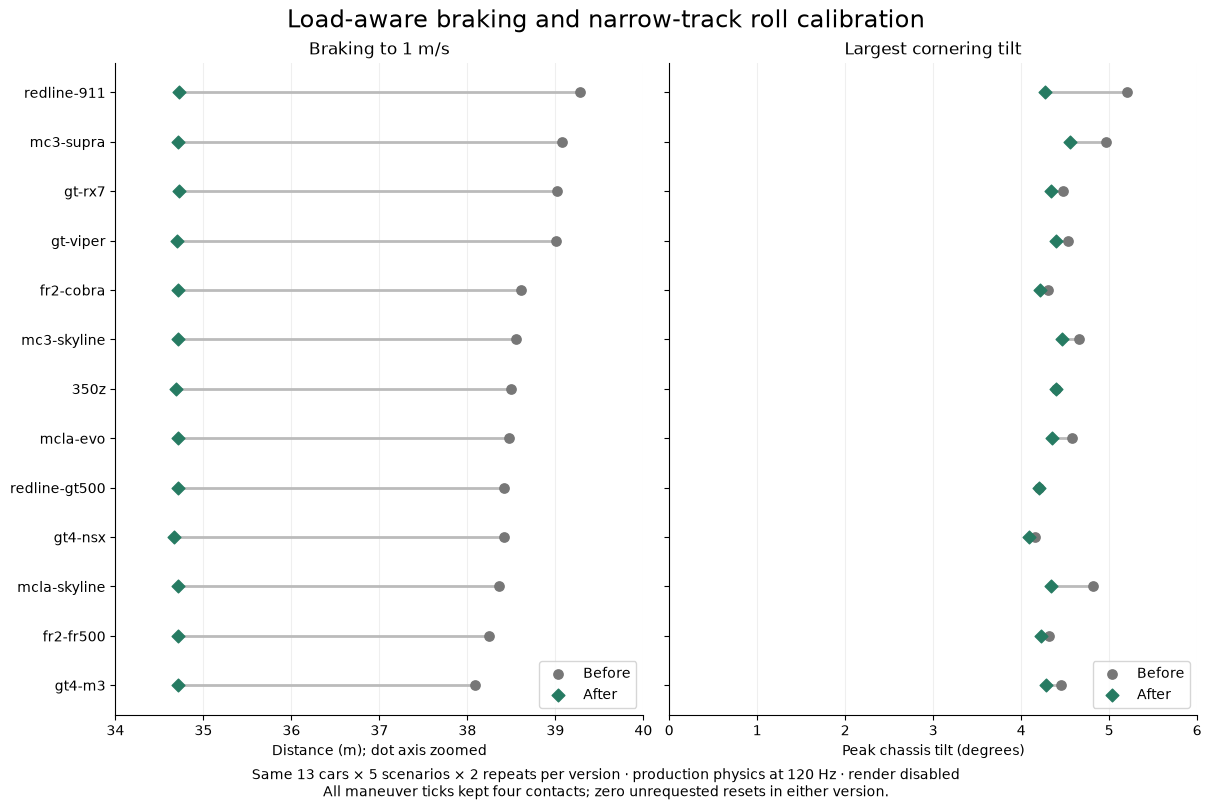

In [4]:
cars=sorted({r["car"] for r in rows},key=lambda c:-by[c,"brake"]["before_near_stop_m"])
turns=["turn-left","turn-right","fast-left","fast-right"]
plt.rcParams.update({"font.size":10,"axes.spines.top":False,"axes.spines.right":False})
fig,axes=plt.subplots(1,2,figsize=(12,8),sharey=True,layout="constrained")
y=np.arange(len(cars))
for ax,metric,title in [(axes[0],"near_stop_m","Braking to 1 m/s"),(axes[1],"peak_tilt_deg","Largest cornering tilt")]:
    old=[by[c,"brake"]["before_"+metric] if metric=="near_stop_m" else max(by[c,case]["before_"+metric] for case in turns) for c in cars]
    new=[by[c,"brake"]["after_"+metric] if metric=="near_stop_m" else max(by[c,case]["after_"+metric] for case in turns) for c in cars]
    for index,(a,b) in enumerate(zip(old,new)):
        ax.plot([a,b],[index,index],color="#bbbbbb",lw=2)
    ax.scatter(old,y,label="Before",color="#777777",s=45,zorder=3)
    ax.scatter(new,y,label="After",color="#267b62",marker="D",s=42,zorder=4)
    ax.set_title(title)
    ax.grid(axis="x",alpha=.2)
    ax.legend(loc="lower right")
axes[0].set_yticks(y,cars);axes[0].invert_yaxis()
axes[0].set_xlabel("Distance (m); dot axis zoomed");axes[0].set_xlim(34,40)
axes[1].set_xlabel("Peak chassis tilt (degrees)");axes[1].set_xlim(0,6)
fig.suptitle("Load-aware braking and narrow-track roll calibration",fontsize=17)
fig.supxlabel("Same 13 cars × 5 scenarios × 2 repeats per version · production physics at 120 Hz · render disabled\n"
              "All maneuver ticks kept four contacts; zero unrequested resets in either version.",fontsize=10)
fig.savefig(OUT/"before-after.png",dpi=150)
plt.show()

### Steering response, speed retention and pitch tradeoffs

In [5]:
text=["| 911 case | Tilt ° before → after | Heading ° before → after | Exit m/s before → after |","|---|---:|---:|---:|"]
for case in ["brake",*turns]:
    r=by["redline-911",case]
    tilt=f"{r['before_peak_tilt_deg']:.2f} → {r['after_peak_tilt_deg']:.2f}"
    yaw=f"{r['before_turn_deg']:.2f} → {r['after_turn_deg']:.2f}" if 'before_turn_deg' in r else "—"
    speed=f"{r['before_turn_exit_mps']:.2f} → {r['after_turn_exit_mps']:.2f}" if 'before_turn_exit_mps' in r else "—"
    text.append(f"| {case} | {tilt} | {yaw} | {speed} |")
display(Markdown("\n".join(text)))
assert all(r['after_four_contact_pct']==100 for r in rows)
assert all(r['after_unexpected_resets']==0 for r in rows)
assert all(r['delta_near_stop_m']<0 for r in rows if r['case']=='brake')
print("Braking improved for every car. All 130 candidate runs passed; complete CSV includes all 65 car/case pairs.")

| 911 case | Tilt ° before → after | Heading ° before → after | Exit m/s before → after |
|---|---:|---:|---:|
| brake | 1.71 → 2.04 | — | — |
| turn-left | 4.89 → 4.01 | 75.21 → 71.23 | 17.22 → 18.36 |
| turn-right | 4.89 → 4.01 | 75.21 → 71.23 | 17.22 → 18.36 |
| fast-left | 5.21 → 4.27 | 46.74 → 43.99 | 26.03 → 26.61 |
| fast-right | 5.21 → 4.27 | 46.74 → 43.99 | 26.03 → 26.61 |

Braking improved for every car. All 130 candidate runs passed; complete CSV includes all 65 car/case pairs.


## Takeaways

The brake change fixes lost braking force caused by the fixed axle split. The roll change deliberately recalibrates the narrow-track cars; it preserves geometry and vertical spring rates but alters cornering behavior. The 911 retains more speed and generates less yaw and slip during these full-throttle turns. Stronger braking also increases pitch slightly. These are measured tradeoffs, not evidence that every handling dimension improved.

The initial flat-road feedback loop and regression test reproduce the production fleet extrema. Raw input/health/course checks cover every candidate run; the notebook independently recalculates the 911 and baseline examples. Full release/GPU verification results and exact source/binary identities are linked in the accompanying report. Source originals were located locally for this follow-up, allowing full asset-preservation checks.

To repeat the numerical experiment, build the CLI, run `tools/run_handling_study.py` with a fresh output directory, audit it with `tools/analyze_handling_study.py`, then compare with `tools/compare_handling_studies.py`. To repeat the reduced repro, run `cargo run --example handling_probe -- --check`.